<div align="center"> 

---



# **Cerebellum Mega Analysis**


<img src="https://static.wixstatic.com/media/da4857_5f6dbdb6bbd84328b1e31c7f2dafb673~mv2.png/v1/fill/w_224,h_226,al_c,q_85,usm_0.66_1.00_0.01,enc_auto/enigma_addiction-300x249.png" alt="image" style="width:300px;"/>


 </img>
</div>


---
# <u> **Project Description:**</u>

The aim of this study is to perform a multi-site mega/meta analysis to asses the effects of substance use on volumetric changes in cerebellar regions (and far beyond). 

## **Hypothesis to test**

**Variables to consider:** 
  - Age
  - Sex
  - Polysubstance use : Smoke and alcohol
  
  
  **Analysis:**
   1. Volume comparisons between-groups of:
   - cerebellum regions

2. Main effects: Acapulco atlas
- Cerebellar volume ~ any drug
- Cerebellar volume ~ drug type

3. Interaction effects: Cerebellum volume
- group * sex
- group + age + sex

4. Partial Least Square: Cerebral - cerebellar association
- MDTB atlas

---

## **1. Autenticate with your google drive credentials** 

This is very important since it is the only way we have to acces the files inside google drive. Run the next two cells and make sure of granting permisions to view, access, and modify google drive files (mark all the tick boxes).

---

In [1]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1) # to turn off warnings
#options(warn=0) # to turn on warnings
options(repr.plot.width=15, repr.plot.height=12) # to resize plots

1 
1

### **1.1 Downloading and loading from google**

The following block of code is to be completed in the future according to the needs of the project.
The main idea is to dowload to this session all the necessary files from google drive that will be used. The downloaded files are: 

- ACAPULCO_Cerebellum_ segmentation_QC.xlsx
- Inclusion_Exclusion_updated.xlsx

In [2]:
# # """""""""""""""""""""""""""""""""""""""|
# # ACAPULCO_Cerebellum_ segmentation_QC ""|
# # """""""""""""""""""""""""""""""""""""""-

# # Acapulco QC
# acapulco_qc_id <- drive_find(n_max=1,pattern = "Cerebellum_segmentation_QC")$id %>%
#  as_id()

#  drive_download(file = acapulco_qc_id,overwrite = T)

# # Demographic data
#  inclusion_exclusion_id <- drive_find(type="xlsx",
#                                       pattern="Inclusion")$id %>%
#             as_id()

# drive_download(inclusion_exclusion_id,overwrite = T)

In [3]:
# # Download Cerebellar volumes folders
# # Tengo que modificar estas lineas para que yo tambien pueda bajar los archivos ya que tengo urls distintas en mi drive

# Acapulco <- "https://drive.google.com/drive/folders/1n7Fmu-S3S4y2Z4eOxwla8Ho5aRQoamkW"
# folder_id <- drive_get(as_id(Acapulco))
# files <- drive_ls(folder_id)

# #loop dirs and download files inside them
# for (i in seq_along(files$name)) {
#   i_dir = drive_ls(files[i, ])
#   dir.create(files$name[i])
#   for (file_i in seq_along(i_dir$name)) {
#     try({
#       drive_download(
#         as_id(i_dir$id[file_i]),
#         path = str_c(files$name[i], "/", i_dir$name[file_i]),
#       overwrite = T)
#     })
#   }
# }

## **2. Load  R packages and dependencies.** 

---

### The following packages are needed:

In [4]:
# Make sure to install pacman before we begin
  if (!require("pacman")) {
  install.packages("pacman")
  }

# Load required packages  
  pacman::p_load(tidyverse,devtools,readxl,
                ggpubr,cowplot,gtsummary,ggthemes,scales,mice,vtreat,sjmisc,
                ggcorrplot,olsrr,lme4,rstatix,janitor)

#devtools::install_github("eliocamp/ggnewscale@dev")
library(ggnewscale)

# NeuroCombat
 if (!require("neuroCombat")){
   devtools::install_github("jfortin1/neuroCombat_Rpackage") }


# Load NeuroCombat
library(neuroCombat)

Loading required package: pacman

Loading required package: neuroCombat



### Set settings for plotting

In [5]:
pal_sex <- c(alpha("#8E5A9C",1),alpha("#2879BC",1))
pal_user <- c(alpha("#757575",1),alpha("#059DC7",1))
pal_substances <- c("HC" = alpha("#757575",1), "ALC" = alpha("#C93F4D",1), 
    "ATS" = alpha("#EB8F33",1), "CANN" = alpha("#0B8755",1), 
    "COC" = alpha("#3A5589",1), "NIC" = alpha("#764EA1",1),
    "OPI" = alpha("#06AED5",1))

---
##  **3. Load, summarize & Plot the data.** 

Before we begin is necessary to explore data and to get a general idea about our ramaining sample after quality control.

The following analysis will consist in summarizing things. Therefore first we will proceed to:

  - Summarize and visualize included and discarted images **per substance**. 
  - Summarize and visualize demographic/clinical data.
  - Summarize and visualize control vs experimental (all substances) groups data.
  - Load, summarize and visualize cerebellum volumes.
  - Dealing with missing data.

In [6]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum")

### **3.1 Read Data**

In this step we read the QC file into a single dataframe.

In [7]:
`%notin%` <- Negate(`%in%`)

ACAPULCO_QC <- map_df(1:7,~read_excel("Data/ACAPULCO_Cerebellum_segmentation_QC.xlsx", sheet = .x),s) %>%
  add_column(Enigma_file = paste(.$Database,.$Subject_ID,sep = '_'),
  .before="Subject_ID") %>%
  arrange(Database)
ACAPULCO_QC$Database <- as.factor(ACAPULCO_QC$Database)

# Homogenize exclude variable
ACAPULCO_QC$`Exclude` <- tolower(ACAPULCO_QC$`Exclude`)
ACAPULCO_QC$`Exclude`[ACAPULCO_QC$`Exclude` == "yes"] <- "exclude"
ACAPULCO_QC$Some_Issue <- if_else(ACAPULCO_QC$`Exclude` %notin% c("no","exclude"),1,0 )

In [8]:
demographics <- read_xlsx("Data/Inclusion_Exclusion_demographics.xlsx", na = c("n/a","NA","na"),
                    sheet = 1,col_types = "guess",trim_ws = T) %>% 
                filter(Exclude != "exclude") %>% 
                select(c("Substance","ID_MRI","Control","Site","Smoker","Age","Sex")) %>%
                inner_join(ACAPULCO_QC %>% select(c("Database","Name_ID","Exclude")),by = c("ID_MRI" = "Name_ID")) %>% 
                filter(Exclude != "exclude")

demographics2 <- read_xlsx("Data/Inclusion_Exclusion_demographics.xlsx", na = c("n/a","NA","na"),
                    sheet = 1,col_types = "guess",trim_ws = T) %>% 
                filter(Exclude != "exclude") %>% 
                select(c("Substance","ID_MRI","Control","Site","Smoker","Age","Sex","Handedness","Education","Other SUD")) %>%
                inner_join(ACAPULCO_QC %>% select(c("Database","Name_ID","Exclude")),by = c("ID_MRI" = "Name_ID")) %>% 
                filter(Exclude != "exclude")

New names:
• `ICV` -> `ICV...31`
• `LThickness` -> `LThickness...100`
• `RThickness` -> `RThickness...101`
• `LSurfArea` -> `LSurfArea...102`
• `RSurfArea` -> `RSurfArea...103`
• `ICV` -> `ICV...104`
• `LThickness` -> `LThickness...173`
• `RThickness` -> `RThickness...174`
• `LSurfArea` -> `LSurfArea...175`
• `RSurfArea` -> `RSurfArea...176`
• `ICV` -> `ICV...177`
New names:
• `ICV` -> `ICV...31`
• `LThickness` -> `LThickness...100`
• `RThickness` -> `RThickness...101`
• `LSurfArea` -> `LSurfArea...102`
• `RSurfArea` -> `RSurfArea...103`
• `ICV` -> `ICV...104`
• `LThickness` -> `LThickness...173`
• `RThickness` -> `RThickness...174`
• `LSurfArea` -> `LSurfArea...175`
• `RSurfArea` -> `RSurfArea...176`
• `ICV` -> `ICV...177`


### **3.2 Summarize Subjects**

In [9]:
# Summarize number of subjects
acapulco_summary <- ACAPULCO_QC %>%
   group_by(Cohort) %>%
   summarize(Size = n(),Included=sum(`Exclude`=="no",na.rm = T),
                    Excluded=sum(`Exclude` == "exclude",na.rm = T),
                    Some_Issue = sum(Some_Issue)) %>%
                    arrange(Size)
# Generate A summary per database

    #acapulco_summary
# Generate barplot
plt1.summary <- acapulco_summary %>%
                pivot_longer(names_to= "Status", values_to = "Count",3:5) %>%
                ggplot(aes(Cohort,Count, fill = Status))+
                geom_bar(position = "stack", stat = "identity")+
                scale_fill_manual(values = c("tomato1","mediumseagreen","skyblue2"))+
                ggtitle("Status of acapulco images")+
                theme_minimal()+
                theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1,size = 30 ,
                face = "bold"))

# repeat plot by cohort
plt2.summary <- ACAPULCO_QC %>%
    group_by(Cohort,Database) %>%
   summarize(Size = n(),Included=sum(`Exclude`=="no",na.rm = T),
                    Excluded=sum(`Exclude` == "exclude",na.rm = T),
                    Some_Issue = sum(Some_Issue)) %>%
                    arrange(Size) %>%
                pivot_longer(names_to= "Status", values_to = "Count",4:6) %>%
                ggplot(aes(Database,Count, fill = Status))+
                geom_bar(position = "stack", stat = "identity")+
                scale_fill_manual(values = c("tomato1","mediumseagreen","skyblue2"))+
                ggtitle("Status of acapulco images")+
                theme_minimal()+
                theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1,size = 10,face = "bold"))+
                facet_wrap(~Cohort,scales = "free")

`summarise()` has grouped output by 'Cohort'. You can override using the
`.groups` argument.


### **3.3 Visualize Demographic data**

In [10]:
Volumes_all <- demographics %>% 
    mutate(Exclude = case_when(Exclude != "no" ~ "yes", Exclude == "no" ~ Exclude)) %>% group_by(Substance,Exclude) %>% 
    summarise(n = n()) 

Volumes_all$ymax <- cumsum(Volumes_all$n)
Volumes_all$ymin <- c(0, head(Volumes_all$ymax, n=-1))
Volumes_all$labelPosition <- (Volumes_all$ymax + Volumes_all$ymin) / 2

`summarise()` has grouped output by 'Substance'. You can override using the
`.groups` argument.


In [11]:
mainCol <- c(pal_substances[2:7],COH="lightgreen")

Excluded_plot <- ggplot(Volumes_all) +
  geom_rect(
    aes(ymin = cumsum(n) - n, ymax = cumsum(n), 
        xmin = 0, xmax = 1, fill = Substance),
  ) +
  scale_fill_manual(values = mainCol) +
  new_scale_fill() +
  geom_rect(
    aes(ymin = cumsum(n) - n, ymax = cumsum(n), 
        xmin = 1.02, xmax = 1.3, fill = Exclude)) +
  scale_fill_manual(values = alpha(c("#5BC0BE","#5B494E"),0.42)) +
  theme_void() + coord_polar(theta = "y") +
  theme(text = element_text(size = 30)) 

dir.create("Figures/Supplementaries/Figure_S1", recursive = TRUE, showWarnings = FALSE)
ggsave(plot = Excluded_plot,filename = "Figures/Supplementaries/Figure_S1/Excluded_plot.png",
        width = 40, height=30, units="cm", bg = "white", dpi = 300)

### **3.4 Load Cerebellar volumes**

#### Extract eTIV

In [12]:
Cerebellar_etiv_files <- list.files(getwd(), pattern = "Cerebel_vols.csv",
            recursive = TRUE, full.names = TRUE) %>% 
  map(~ suppressMessages(read_csv(.x, show_col_types = FALSE, progress = FALSE))) %>% 
  purrr::reduce(rbind) %>% 
  select(ID, eTIV)

In [13]:
eTIV <- Cerebellar_etiv_files %>% mutate(eTIV = eTIV/1000) %>% 
    drop_na() %>% rename("ID_MRI" = "ID") %>% select(ID_MRI,eTIV)

#### Extract volumes

In [14]:
names_SUD <- list.files(getwd(), pattern = "Cerebel_vols.Corrected.",
                       recursive = TRUE) %>% fs::path_dir() %>% str_extract(".*(?=\\_)")

Cerebellar_files <- list.files(getwd(), pattern = "Cerebel_vols.Corrected.",
                      recursive = TRUE, full.names = TRUE) %>% 
  map(~ suppressMessages(read_csv(.x, show_col_types = FALSE, progress = FALSE))) %>% 
  set_names(names_SUD) %>% 
  purrr::reduce(rbind) %>% 
  select(-1)

### **3.5 Filter database**
For now we will get rid of the data with some issues and as expected. So here we filter data to keep only included subjects

Final file: **Volumes_Cerebellum_raw**

#### Merging all data

In [15]:
# Merging demographics and Acapulco volumes
Volumes_Cerebellum_raw <- demographics %>% 
    inner_join(Cerebellar_files, by = c("ID_MRI" = "ID")) %>% 
    filter(Substance != "COH")

### **3.6 Dealing with NA demographics covariates**

Final file: **Volumes_Cerebellum_imputed**

In [16]:
# Exploratory NA data and export figure
png("Figures/Supplementaries/Figure_S1/md_pattern.png", width = 2400, height = 1800, res = 300)
invisible(mice::md.pattern(Volumes_Cerebellum_raw %>% select(Sex, Age), plot = TRUE, rotate.names = TRUE))
dev.off()

agg_record_255518808 
                   2

In [17]:
Volumes_Cerebellum_raw %>% left_join(eTIV, by = "ID_MRI") %>% 
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>% 
    select(c("Control","Database","Substance","Age")) %>% 
    group_by(Substance) %>% summarise(NA_Count = sum(is.na(Age)))

Volumes_Cerebellum_raw %>% left_join(eTIV, by = "ID_MRI") %>% 
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>% 
    select(c("Control","Database","Substance","Sex")) %>% 
    group_by(Substance) %>% summarise(NA_Count = sum(is.na(Sex)))

Substance,NA_Count
<chr>,<int>
ALC,427
ATS,0
CANN,0
COC,12
HC,10
NIC,76
OPI,0
NA,26


Substance,NA_Count
<chr>,<int>
ALC,426
ATS,0
CANN,0
COC,3
HC,6
NIC,76
OPI,0
NA,18



 iter imp variable
  1   1  Sex  Age
  1   2  Sex  Age
  1   3  Sex  Age
  1   4  Sex  Age
  1   5  Sex  Age
  2   1  Sex  Age
  2   2  Sex  Age
  2   3  Sex  Age
  2   4  Sex  Age
  2   5  Sex  Age
  3   1  Sex  Age
  3   2  Sex  Age
  3   3  Sex  Age
  3   4  Sex  Age
  3   5  Sex  Age
  4   1  Sex  Age
  4   2  Sex  Age
  4   3  Sex  Age
  4   4  Sex  Age
  4   5  Sex  Age
  5   1  Sex  Age
  5   2  Sex  Age
  5   3  Sex  Age
  5   4  Sex  Age
  5   5  Sex  Age


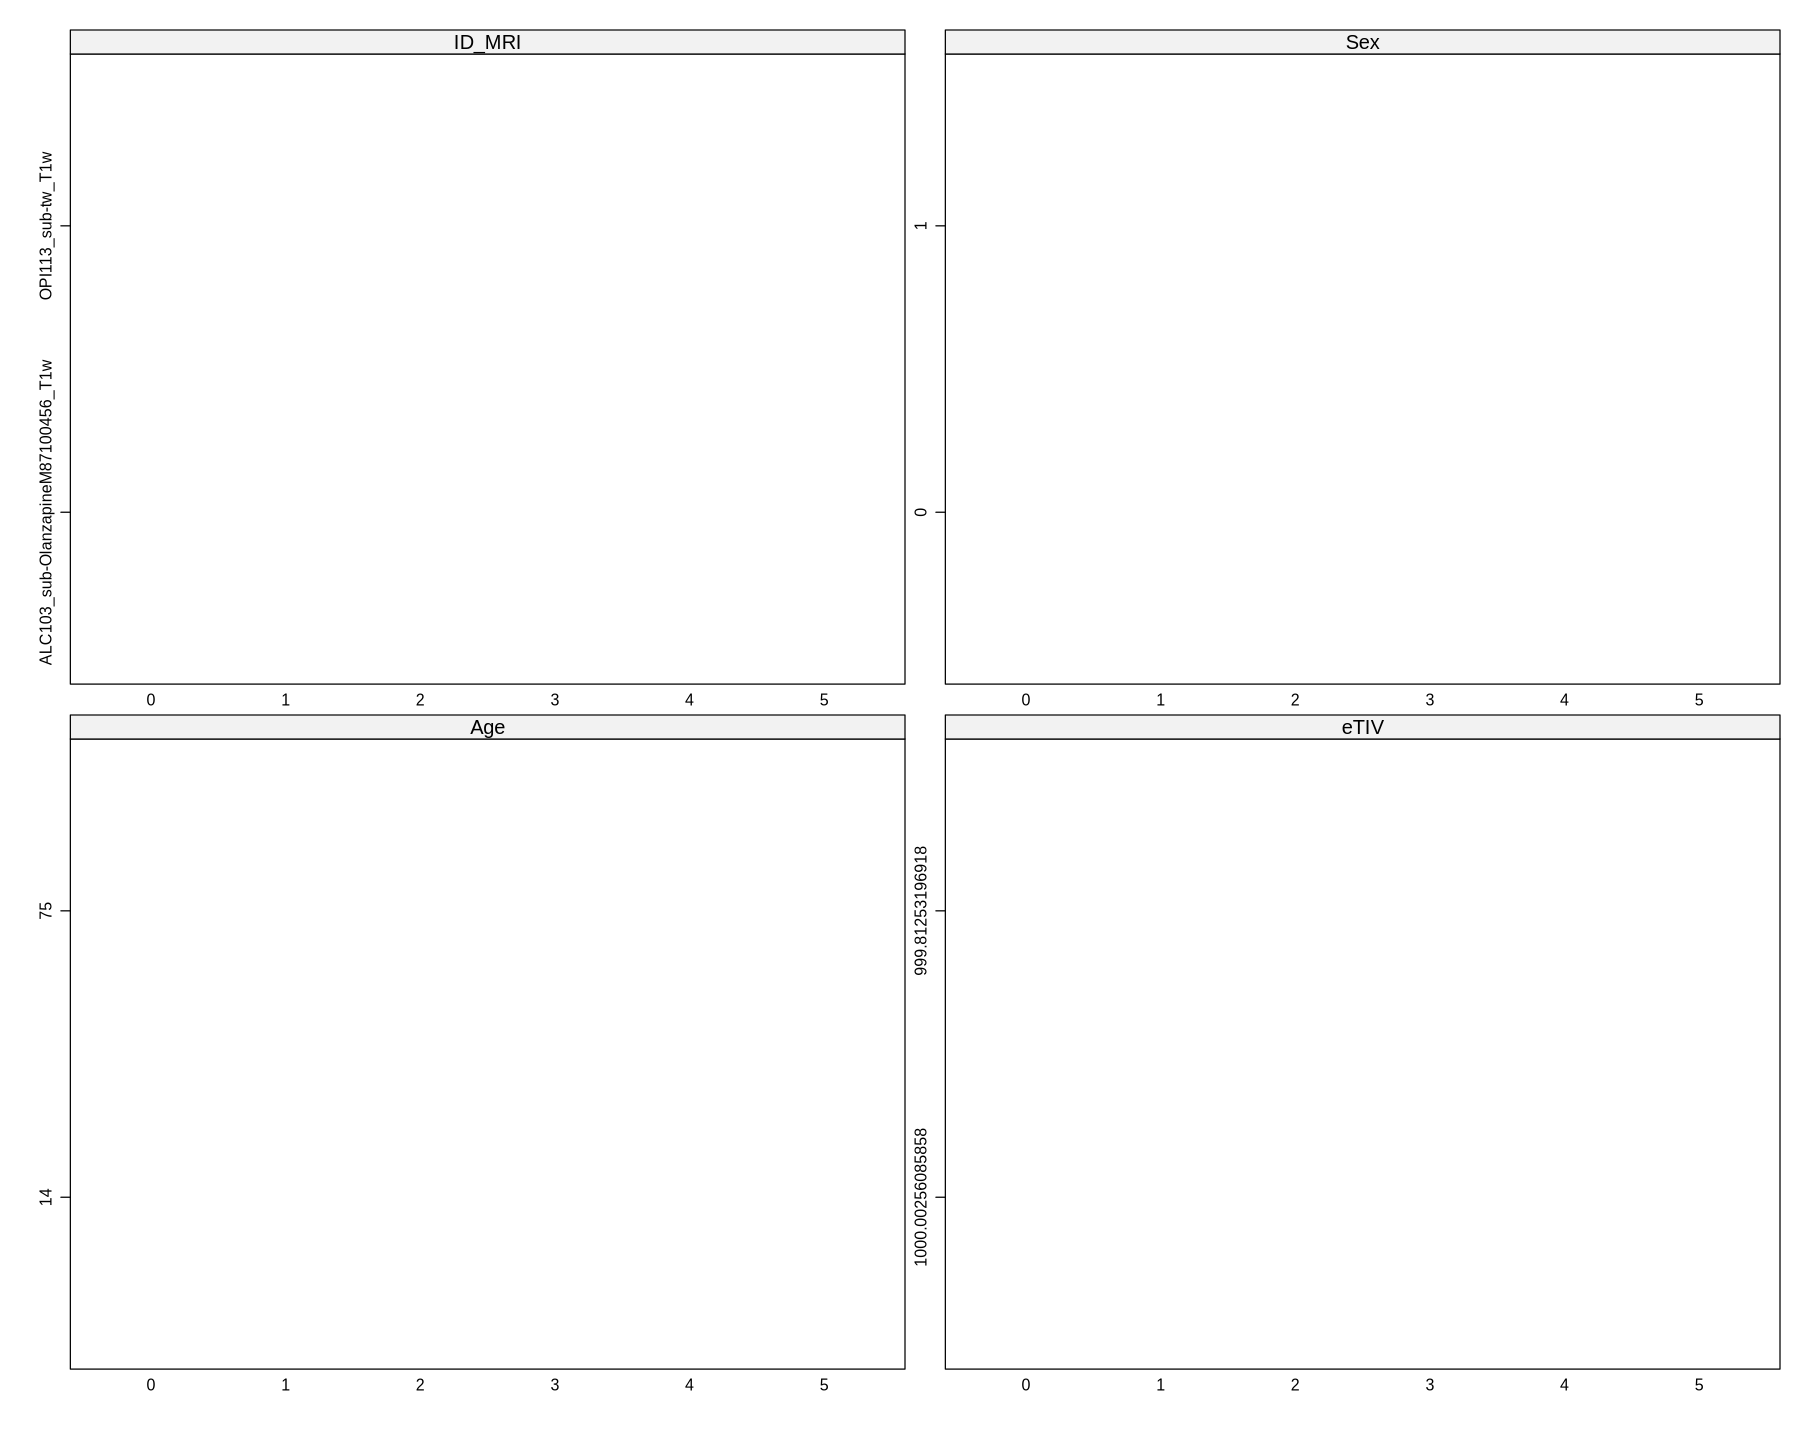

In [18]:
Volumes_Cerebellum_raw_NA <- Volumes_Cerebellum_raw %>% left_join(eTIV, by = "ID_MRI") %>% 
    select(c("ID_MRI","Sex","Age","eTIV"))

# Perform imputation using brain volumes, sex or age as predictors for sex and age
dealing_NA <- mice(Volumes_Cerebellum_raw_NA, 
            m = 5,            
            method = 'pmm',
            seed = 42,
            predictorMatrix = quickpred(Volumes_Cerebellum_raw_NA, include = "eTIV",
                           exclude="ID_MRI")) 

# Dealing MCAR NA data using mice library
Volumes_Cerebellum_raw_NA <- complete(dealing_NA,1)

# Visualizing distribution of all data with NA's
stripplot(dealing_NA, pch = 20, cex = 1.2)

In [19]:
# Replacing NA data with impute data
Volumes_Cerebellum_imputed <- Volumes_Cerebellum_raw %>% select(-c(Sex,Age)) %>% 
    left_join(Volumes_Cerebellum_raw_NA, by = "ID_MRI") %>% mutate(Age = as.integer(Age))

### **3.6b Missingness report by site and diagnostic group**

Reviewers noted that Age and Sex were missing for > 500 participants and that imputation used brain volumes (eTIV) as a predictor — a circular approach when volumes are the outcomes of interest.  
This section reports the extent of missingness stratified by site and substance group before any imputation is applied.


In [20]:

# Missingness report: count and percentage of missing Age and Sex by site and diagnostic group
missingness_report <- Volumes_Cerebellum_raw %>%
    mutate(Substance_label = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    group_by(Database, Substance_label) %>%
    summarise(
        n               = n(),
        n_missing_Age   = sum(is.na(Age)),
        n_missing_Sex   = sum(is.na(Sex)),
        pct_missing_Age = round(100 * mean(is.na(Age)), 1),
        pct_missing_Sex = round(100 * mean(is.na(Sex)), 1),
        .groups = "drop"
    )

dir.create("Statistics/Sanity_check", recursive = TRUE, showWarnings = FALSE)
write_csv(missingness_report, "Statistics/Sanity_check/missingness_by_site_group.csv")
print(missingness_report)


# A tibble: 98 × 7
   Database Substance_label     n n_missing_Age n_missing_Sex pct_missing_Age
   <fct>    <chr>           <int>         <int>         <int>           <dbl>
 1 ALC103   ALC               150             3             4               2
 2 ALC104   ALC               422           422           422             100
 3 ALC106   HC                182             0             0               0
 4 ALC108   ALC                 9             0             0               0
 5 ALC108   HC                 18             0             0               0
 6 ALC109   ALC                40             0             0               0
 7 ALC112   ALC                37             0             0               0
 8 ALC112   HC                 16             0             0               0
 9 ALC113   ALC                27             0             0               0
10 ALC113   HC                 21             0             0               0
# ℹ 88 more rows
# ℹ 1 more variable: pct_mis

### **3.6c Complete-cases dataset (observed Age and Sex only)**

Subjects with missing Age or Sex are excluded entirely. This dataset is used in sensitivity analyses to verify that results do not depend on the imputed covariates.


In [21]:

# Complete-cases dataset: subjects with fully observed Age and Sex (no imputation)
Volumes_Cerebellum_complete_cases <- Volumes_Cerebellum_raw %>%
    filter(!is.na(Age) & !is.na(Sex))

cat("Complete-cases sample size:", nrow(Volumes_Cerebellum_complete_cases),
    "out of", nrow(Volumes_Cerebellum_raw), "total subjects\n")


Complete-cases sample size: 3023 out of 3575 total subjects


### **3.6d Alternative imputation (Substance + Site predictors only — no brain volumes)**

Missing Age and Sex are imputed using only diagnostic group (`Substance`) and scanner site (`Database`) as predictors.  
This avoids the circular use of neuroanatomical volumes (eTIV) to predict covariates that are later used as model covariates.


In [22]:

# Alternative imputation: Age and Sex predicted from Substance + Database only (no brain volumes)
Volumes_Cerebellum_raw_NA_alt <- Volumes_Cerebellum_raw %>%
    left_join(eTIV, by = "ID_MRI") %>%
    mutate(Substance_num = as.numeric(factor(Substance)),
           Database_num  = as.numeric(factor(Database))) %>%
    select(ID_MRI, Sex, Age, Substance_num, Database_num)

dealing_NA_alt <- mice(Volumes_Cerebellum_raw_NA_alt,
            m = 5,
            method = 'pmm',
            seed = 42,
            predictorMatrix = quickpred(Volumes_Cerebellum_raw_NA_alt,
                           include = c("Substance_num", "Database_num"),
                           exclude = "ID_MRI"))

Volumes_Cerebellum_raw_NA_alt <- complete(dealing_NA_alt, 1) %>%
    select(ID_MRI, Sex, Age)

# Merge alternative-imputed Age and Sex back into the raw dataset
Volumes_Cerebellum_alt_imputed <- Volumes_Cerebellum_raw %>%
    select(-c(Sex, Age)) %>%
    left_join(Volumes_Cerebellum_raw_NA_alt, by = "ID_MRI") %>%
    mutate(Age = as.integer(Age))



 iter imp variable
  1   1  Sex  Age
  1   2  Sex  Age
  1   3  Sex  Age
  1   4  Sex  Age
  1   5  Sex  Age
  2   1  Sex  Age
  2   2  Sex  Age
  2   3  Sex  Age
  2   4  Sex  Age
  2   5  Sex  Age
  3   1  Sex  Age
  3   2  Sex  Age
  3   3  Sex  Age
  3   4  Sex  Age
  3   5  Sex  Age
  4   1  Sex  Age
  4   2  Sex  Age
  4   3  Sex  Age
  4   4  Sex  Age
  4   5  Sex  Age
  5   1  Sex  Age
  5   2  Sex  Age
  5   3  Sex  Age
  5   4  Sex  Age
  5   5  Sex  Age


### **3.8 Dealing with QC ROI-excludes**

Final file: **Volumes_Cerebellum_Acapulco_raw**

In [23]:
Volumes_Cerebellum_Acapulco_raw <- Volumes_Cerebellum_imputed %>% mutate(Corpus.Medullare = case_when(!grepl(Exclude,pattern = "cm") ~ Corpus.Medullare), 
                                    Left.Crus.I = case_when(!grepl(Exclude,pattern = "left.crus.i") ~ Left.Crus.I),
                                    Left.Crus.II = case_when(!grepl(Exclude,pattern = "left.crus.ii") ~ Left.Crus.II),
                                    Left.I.III = case_when(!grepl(Exclude,pattern = "left.i.iii") ~ Left.I.III),
                                    Left.IV = case_when(!grepl(Exclude,pattern = "left.iv") ~ Left.IV),
                                    Left.IX = case_when(!grepl(Exclude,pattern = "left.ic") ~ Left.IX),
                                    Left.V = case_when(!grepl(Exclude,pattern = "left.iv") ~ Left.V),
                                    Left.VI = case_when(!grepl(Exclude,pattern = "left.vi") ~ Left.VI),
                                    Left.VIIB = case_when(!grepl(Exclude,pattern = "left.viib") ~ Left.VIIB),
                                    Left.VIIIA = case_when(!grepl(Exclude,pattern = "left.viiia") ~ Left.VIIIA),
                                    Left.VIIIB = case_when(!grepl(Exclude,pattern = "left.viiib") ~ Left.VIIIB),
                                    Left.X = case_when(!grepl(Exclude,pattern = "left.x") ~ Left.X),
                                    Right.Crus.I = case_when(!grepl(Exclude,pattern = "right.crus.i") ~ Right.Crus.I),
                                    Right.Crus.II = case_when(!grepl(Exclude,pattern = "right.crus.ii") ~ Right.Crus.II),
                                    Right.I.III = case_when(!grepl(Exclude,pattern = "right.i.iii") ~ Right.I.III),
                                    Right.IX = case_when(!grepl(Exclude,pattern = "right.ix") ~ Right.IX),
                                    Right.V = case_when(!grepl(Exclude,pattern = "right.v") ~ Right.V),
                                    Right.VI = case_when(!grepl(Exclude,pattern = "right.vi") ~ Right.VI),
                                    Right.VIIB = case_when(!grepl(Exclude,pattern = "right.viib") ~ Right.VIIB),
                                    Right.VIIIA = case_when(!grepl(Exclude,pattern = "right.viiia") ~ Right.VIIIA),
                                    Right.VIIIB = case_when(!grepl(Exclude,pattern = "right.viiib") ~ Right.VIIIB),
                                    Right.X = case_when(!grepl(Exclude,pattern = "right.x") ~ Right.X),
                                    Rigt.IV = case_when(!grepl(Exclude,pattern = "right.iv") ~ Rigt.IV),
                                    Vermis.IX = case_when(!grepl(Exclude,pattern = "vermis.ix") ~ Vermis.IX),
                                    Vermis.VI = case_when(!grepl(Exclude,pattern = "vermis.vi") ~ Vermis.VI),
                                    Vermis.VII = case_when(!grepl(Exclude,pattern = "vermis.vii") ~ Vermis.VII),
                                    Vermis.VIII = case_when(!grepl(Exclude,pattern = "vermis.viii") ~ Vermis.VIII),
                                    Vermis.X = case_when(!grepl(Exclude,pattern = "vermis.x") ~ Vermis.X),
                                    Exclude = case_when(Exclude == "exclude" ~ "yes",Exclude != "exclude" ~ "no")) %>% 
                                select(-c(Site,Smoker,Exclude)) %>%
                                mutate(Database = factor(Database),
                                    Substance = factor(Substance))

## **4 Volumes harmonization using ComBat**

Harmonize through ComBatHarmonization

Final file: **Volumes_Cerebellum_Acapulco_Harmonized**

### **4.1 Explore distributions**

a.k.a. "Harmonization is needed", distributions are normal

In [24]:
# Total_Cerebel_Vol distributions across Database
plot_dist_befComBat_Acapulco <- Volumes_Cerebellum_Acapulco_raw %>%
    mutate(Database = factor(Database)) %>%
    ggplot(aes(x = reorder(Database, Total_Cerebel_Vol, FUN = median, na.rm = TRUE), y = Total_Cerebel_Vol, fill = Database)) +
    geom_violin(trim = FALSE, alpha = 0.6, color = NA) +
    geom_boxplot(width = 0.12, outlier.shape = NA, alpha = 0.9) +
    labs(title = "Total_Cerebel_Vol distribution across Database before Harmonization", x = "Database", y = "Total_Cerebel_Vol (L)") +
    theme_minimal() +
    theme(legend.position = "none",
                axis.text.x = element_text(angle = 45, hjust = 1)) 

ggsave(plot=plot_dist_befComBat_Acapulco,filename = "Figures/Supplementaries/Figure_S1/Acapulco_Total_Cerebel_Vol_distributions_before_harmonization.png",
        width = 21, height = 10, units = "cm", bg = "white", dpi = 300)

### **4.2 ComBat Harmonization**

In [25]:
# Harmonization volumes controling for Age, Sex
# Note: volumes are already corrected by eTIV
mod <- model.matrix(~Volumes_Cerebellum_Acapulco_raw$Age+Volumes_Cerebellum_Acapulco_raw$Sex)

Volumes_Cerebellum_Harmonized <- neuroCombat(dat = t(Volumes_Cerebellum_Acapulco_raw %>% select(contains("."),eTIV,Total_Cerebel_Vol)), 
                    batch = Volumes_Cerebellum_Acapulco_raw$Database, mean.only=TRUE, mod=mod, parametric=TRUE)

Volumes_Cerebellum_Acapulco_Harmonized <- Volumes_Cerebellum_Harmonized$dat.combat %>% t() %>% as_tibble() %>% 
                      add_column(Volumes_Cerebellum_Acapulco_raw %>% select(-c(contains("."),eTIV,Total_Cerebel_Vol)),.before = 1) %>% 
                    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>% 
                    filter(!is.na(Substance)) %>% mutate(Sex = round(Sex,0)) %>% 
                    mutate(Sex = factor(Sex,levels = c("0","1")))

[neuroCombat] Found 653 missing data values. 
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 55 batches
[neuroCombat] Adjusting for  2  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data


### **4.3 Explore distributions after ComBat**

In [26]:
# Total_Cerebel_Vol distributions across Database
plot_dist_aftComBat_Acapulco <- Volumes_Cerebellum_Acapulco_Harmonized %>%
    mutate(Database = factor(Database)) %>%
    ggplot(aes(x = reorder(Database, Total_Cerebel_Vol, FUN = median, na.rm = TRUE), y = Total_Cerebel_Vol, fill = Database)) +
    geom_violin(trim = FALSE, alpha = 0.6, color = NA) +
    geom_boxplot(width = 0.12, outlier.shape = NA, alpha = 0.9) +
    labs(title = "Total_Cerebel_Vol distribution across Database after Harmonization", x = "Database", y = "Total_Cerebel_Vol (L)") +
    theme_minimal() +
    theme(legend.position = "none",
                axis.text.x = element_text(angle = 45, hjust = 1)) 

ggsave(plot=plot_dist_aftComBat_Acapulco,filename = "Figures/Supplementaries/Figure_S1/Acapulco_Total_Cerebel_Vol_distributions_after_harmonization.png",
        width = 21, height = 10, units = "cm", bg = "white", dpi = 300)

## **5 Data preparation for MDTB atlas**

Based on the Volumes_Cerebellum_Acapulco dataset

Final file: **Volumes_Cerebellum_MDTB_Harmonized**

### **5.0 Load data**

In [27]:
names_SUD <- list.files(paste0(getwd(),"/Data/MDTB/"))

if (file.exists("Data/MDTB_cerebellar_files.csv")) {
    MDTB_cerebellar_files <- read_csv("Data/MDTB_cerebellar_files.csv")
} else {
    MDTB_cerebellar_files <- names_SUD %>% 
        map(~ list.files(paste0(getwd(),"/Data/MDTB/",.x), full.names = TRUE, recursive = TRUE)) %>% 
        map(~ map(.,~ .x %>% read.table(sep = "\t", header = TRUE) %>% mutate(ID_MRI = tools::file_path_sans_ext(basename(.x))))) %>% 
        map(~ .x %>% purrr::reduce(rbind) %>% select(ID_MRI,region,nanmean)) %>%
        map(~ .x %>% spread(region,nanmean,sep = "_")) %>% 
        set_names(names_SUD) %>% reduce(rbind)
}

Rows: 4904 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): ID_MRI
dbl (10): region_1, region_2, region_3, region_4, region_5, region_6, region...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [28]:
Volumes_Cerebellum_MDTB_raw <- Volumes_Cerebellum_Acapulco_Harmonized %>% 
    select(c("Substance","ID_MRI","Control","Database","Sex","Age","eTIV")) %>% 
    left_join(MDTB_cerebellar_files, by = "ID_MRI")

### **5.1 Explore distributions**

In [29]:
# region_1 distributions across Database
plot_dist_befComBat_MDTB <- Volumes_Cerebellum_MDTB_raw %>%
    mutate(Database = factor(Database)) %>%
    ggplot(aes(x = reorder(Database, region_1, FUN = median, na.rm = TRUE), y = region_1, fill = Database)) +
    geom_violin(trim = FALSE, alpha = 0.6, color = NA) +
    geom_boxplot(width = 0.12, outlier.shape = NA, alpha = 0.9) +
    labs(title = "region_1 distribution across Database before Harmonization", x = "Database", y = "region_1 (L)") +
    theme_minimal() +
    theme(legend.position = "none",
                axis.text.x = element_text(angle = 45, hjust = 1)) 

ggsave(plot=plot_dist_befComBat_MDTB,filename = "Figures/Supplementaries/Figure_S1/MDTB_region_1_distributions_before_harmonization.png",
        width = 21, height = 10, units = "cm", bg = "white", dpi = 300)

### **5.2 ComBat Harmonization**

In [30]:
mod <- model.matrix(~Volumes_Cerebellum_MDTB_raw$Age+Volumes_Cerebellum_MDTB_raw$Sex+Volumes_Cerebellum_MDTB_raw$eTIV)
Volumes_Cerebellum_MDTB_Harmonized <- neuroCombat(dat = t(Volumes_Cerebellum_MDTB_raw %>% select(contains("region"))), 
                    batch = Volumes_Cerebellum_MDTB_raw$Database,mean.only=TRUE, mod=mod, parametric=TRUE)

Volumes_Cerebellum_MDTB_Harmonized <- Volumes_Cerebellum_MDTB_Harmonized$dat.combat %>% t() %>% as_tibble() %>% 
                    add_column(Volumes_Cerebellum_MDTB_raw %>% select(-contains("region")),.before = 1) %>% 
                    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>% select(-eTIV)

[neuroCombat] Found 770 missing data values. 
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 55 batches
[neuroCombat] Adjusting for  3  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data


### **5.3 Explore distributions after ComBat**

In [31]:
# region_1 distributions across Database
plot_dist_aftComBat_MDTB <- Volumes_Cerebellum_MDTB_Harmonized %>%
    mutate(Database = factor(Database)) %>%
    ggplot(aes(x = reorder(Database, region_1, FUN = median, na.rm = TRUE), y = region_1, fill = Database)) +
    geom_violin(trim = FALSE, alpha = 0.6, color = NA) +
    geom_boxplot(width = 0.12, outlier.shape = NA, alpha = 0.9) +
    labs(title = "region_1 distribution across Database after Harmonization", x = "Database", y = "region_1 (L)") +
    theme_minimal() +
    theme(legend.position = "none",
                axis.text.x = element_text(angle = 45, hjust = 1)) 

ggsave(plot=plot_dist_aftComBat_MDTB,filename = "Figures/Supplementaries/Figure_S1/MDTB_region_1_distributions_after_harmonization.png",
        width = 21, height = 10, units = "cm", bg = "white", dpi = 300)

## **6 Data preparation for DK atlas**

Final file: **Volumes_Cerebral_DK_Harmonized**

### **6.0 Load data**

In [32]:
Volumes_Cerebral_DK_raw <- read_csv("Data/DK/lh_volumes_DKTatlas.csv") %>% 
    left_join(read_csv("Data/DK/rh_volumes_DKTatlas.csv")) %>% 
    filter(!Substance %in% c("COH")) %>% 
    select("Subj",contains("lh"), contains("rh")) %>% 
    rename("ID_MRI" = "Subj") %>% 
    mutate(across(contains("lh_") | contains("rh_"), ~ . / 1000))

Volumes_Cerebral_DK_raw <- Volumes_Cerebellum_Acapulco_Harmonized %>% select(-contains(".")) %>% 
    left_join(Volumes_Cerebral_DK_raw %>% drop_na(), by = c("ID_MRI")) %>% drop_na()

Rows: 3419 Columns: 45
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): Subj, Substance, Database, Exclude, InputFile
dbl (40): Site, Age, Sex, Total_Cerebel_Vol, lh_bankssts_volume, lh_caudalan...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 3419 Columns: 45
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): Subj, Substance, Database, Exclude, InputFile
dbl (40): Site, Age, Sex, Total_Cerebel_Vol, rh_bankssts_volume, rh_caudalan...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Joining with `by = join_by(Subj, Substance, Database, Site, Age, Sex, Exclude,
Total_Cerebel_Vol, InputFile, BrainSegVolNotVent, eTIV)`


### **6.1 Explore distributions**

In [33]:
# lh_fusiform_volume distributions across Database
plot_dist_befComBat_DK <- Volumes_Cerebral_DK_raw %>%
    mutate(Database = factor(Database)) %>%
    ggplot(aes(x = reorder(Database, lh_fusiform_volume, FUN = median, na.rm = TRUE), y = lh_fusiform_volume, fill = Database)) +
    geom_violin(trim = FALSE, alpha = 0.6, color = NA) +
    geom_boxplot(width = 0.12, outlier.shape = NA, alpha = 0.9) +
    labs(title = "lh_fusiform_volume distribution across Database before Harmonization", x = "Database", y = "lh_fusiform_volume (L)") +
    theme_minimal() +
    theme(legend.position = "none",
                axis.text.x = element_text(angle = 45, hjust = 1)) 

ggsave(plot=plot_dist_befComBat_DK,filename = "Figures/Supplementaries/Figure_S1/DK_lh_fusiform_volume_distributions_before_harmonization.png",
        width = 21, height = 10, units = "cm", bg = "white", dpi = 300)

### **6.2 ComBat Harmonization**

In [34]:
mod <- model.matrix(~Volumes_Cerebral_DK_raw$Age+Volumes_Cerebral_DK_raw$Sex+Volumes_Cerebral_DK_raw$eTIV)
Volumes_Cerebral_DK_Harmonized <- neuroCombat(dat = t(Volumes_Cerebral_DK_raw %>% select(contains("lh"), contains("rh"))), 
                    batch = Volumes_Cerebral_DK_raw$Database,mean.only=TRUE, mod=mod, parametric=TRUE)

Volumes_Cerebral_DK_Harmonized <- Volumes_Cerebral_DK_Harmonized$dat.combat %>% t() %>% as_tibble() %>% 
                    add_column(Volumes_Cerebral_DK_raw %>% select(-contains("lh"), -contains("rh")),.before = 1) %>% 
    filter(!Substance %in% c("COH"))

[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 55 batches
[neuroCombat] Adjusting for  3  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data


### **6.3 Explore distributions after ComBat**

In [35]:
# lh_fusiform_volume distributions across Database
plot_dist_aftComBat_DK <- Volumes_Cerebral_DK_Harmonized %>%
    mutate(Database = factor(Database)) %>%
    ggplot(aes(x = reorder(Database, lh_fusiform_volume, FUN = median, na.rm = TRUE), y = lh_fusiform_volume, fill = Database)) +
    geom_violin(trim = FALSE, alpha = 0.6, color = NA) +
    geom_boxplot(width = 0.12, outlier.shape = NA, alpha = 0.9) +
    labs(title = "lh_fusiform_volume distribution across Database after Harmonization", x = "Database", y = "lh_fusiform_volume (L)") +
    theme_minimal() +
    theme(legend.position = "none",
                axis.text.x = element_text(angle = 45, hjust = 1)) 

ggsave(plot=plot_dist_aftComBat_DK,filename = "Figures/Supplementaries/Figure_S1/DK_lh_fusiform_volume_distributions_after_harmonization.png",
        width = 21, height = 10, units = "cm", bg = "white", dpi = 300)

## **7 Save**

In [36]:
dir.create("Data/RData/", recursive = TRUE,showWarnings = FALSE)
if (!file.exists("Data/RData/Volumes_Cerebellum.RData")) {
    save(Volumes_Cerebellum_Acapulco_raw, Volumes_Cerebellum_Acapulco_Harmonized, 
             Volumes_Cerebellum_MDTB_raw, Volumes_Cerebellum_MDTB_Harmonized,
             Volumes_Cerebral_DK_raw, Volumes_Cerebral_DK_Harmonized,
             demographics,demographics2,
             file = "Data/RData/Volumes_Cerebellum.RData")
}

# Save plots in an RData
dir.create("Data/RData/Plots/", recursive = TRUE,showWarnings = FALSE)
if (!file.exists("Data/RData/Plots/Acapulco_MDTB_DK_Plots.RData")) {
    save(Excluded_plot, 
        plot_dist_befComBat_Acapulco, plot_dist_aftComBat_Acapulco,
        plot_dist_befComBat_MDTB, plot_dist_aftComBat_MDTB,
        plot_dist_befComBat_DK, plot_dist_aftComBat_DK,
        file = "Data/RData/Plots/Acapulco_MDTB_DK_Plots.RData")
}

In [37]:
data_out <- list(
    Volumes_Cerebellum_Raw = Volumes_Cerebellum_Acapulco_raw,
    Volumes_Cerebellum_Acapulco_Harmonized = Volumes_Cerebellum_Acapulco_Harmonized,
    Volumes_Cerebellum_MDTB_Harmonized = Volumes_Cerebellum_MDTB_Harmonized,
    Volumes_Cerebral_DK_Harmonized = Volumes_Cerebral_DK_Harmonized
)

purrr::iwalk(data_out, ~ {
    path <- file.path("Data", paste0(.y, ".csv"))
    if (file.exists(path)) file.remove(path)
    write_csv(.x, path)
})

In [38]:
Volumes_Cerebellum_Acapulco_Harmonized %>% 
    group_by(Substance) %>% 
    summarize(
        n = n(),
        mean_age = mean(Age, na.rm = TRUE),
        sd_age = sd(Age, na.rm = TRUE),
        n_male = sum(Sex == 1, na.rm = TRUE),
        n_female = sum(Sex == 0, na.rm = TRUE),
        n_databases = n_distinct(Database)
    ) %>%
    print()

# A tibble: 7 × 7
  Substance     n mean_age sd_age n_male n_female n_databases
  <chr>     <int>    <dbl>  <dbl>  <int>    <int>       <int>
1 ALC         914     34.0  11.5     660      254          13
2 ATS         111     29.6   9.98     83       28           6
3 CANN        275     28.1   9.64    190       85          10
4 COC         405     37.6   9.28    318       87          12
5 HC         1177     30.7  11.4     825      352          41
6 NIC         579     29.7  10.0     312      267          11
7 OPI          58     36.5   8.41     36       22           2


In [39]:
Volumes_Cerebellum_Acapulco_Harmonized %>% 
    filter(Substance != "OPI") %>%
    summarize(
        n = n(),
        mean_age = mean(Age, na.rm = TRUE),
        sd_age = sd(Age, na.rm = TRUE),
        n_male = sum(Sex == 1, na.rm = TRUE),
        n_female = sum(Sex == 0, na.rm = TRUE),
        n_databases = n_distinct(Database)
    ) %>%
    print()

# A tibble: 1 × 6
      n mean_age sd_age n_male n_female n_databases
  <int>    <dbl>  <dbl>  <int>    <int>       <int>
1  3461     32.0   11.1   2388     1073          55


---
## **8. Sanity Check datasets: complete-cases and alternative imputation**

Two additional harmonized datasets are produced to address reviewer concerns:
- **CC** (Complete Cases): subjects with observed Age and Sex only — no imputation
- **AI** (Alternative Imputation): Age/Sex imputed using Substance group and Site only, without neuroanatomical predictors

Both datasets go through the same ROI quality-control, ComBat harmonization, and MDTB/DK atlas processing as the primary data.


---
## **8. Covariate Preparation for Residualization (CA variant)**

This section prepares covariates for subject-stratified residualization. Following reviewer feedback, we remove effects of polysubstance exposure, smoking, education, and handedness on cerebellar volumes before harmonization.

**Steps:**
1. Parse "Other SUD" column → create binary substance indicators
2. Encode categorical variables: Handedness (numeric), Smoker (binary)
3. Center and scale continuous variables: Age, Education
4. Assess missing data; drop covariates >80% missing
5. Stratify subjects by covariate completeness (max → min available covariates)
6. Create demographics2_cleaned for residualization pipeline

---

In [40]:
# ---- Phase 0: Covariate Preparation for CA (Covariate-Adjusted) variant ----

# Step 0.1: Parse "Other SUD" column and create binary substance indicators
parse_other_sud <- function(sud_string) {
  if (is.na(sud_string)) {
    return(list(ALC = NA, ATS = NA, CANN = NA, COC = NA, NIC = NA, OPI = NA))
  }

  result <- list(ALC = FALSE, ATS = FALSE, CANN = FALSE, COC = FALSE, NIC = FALSE, OPI = FALSE)

  if (sud_string == "" | tolower(sud_string) == "none") {
    return(result)
  }

  sud_string <- tolower(sud_string)
  substances <- unlist(strsplit(sud_string, "[,\\s]+"))
  substances <- substances[substances != ""]

  for (subst in substances) {
    if (grepl("alc", subst)) result$ALC <- TRUE
    if (grepl("ats", subst)) result$ATS <- TRUE
    if (grepl("cann|cannabis", subst)) result$CANN <- TRUE
    if (grepl("coc", subst)) result$COC <- TRUE
    if (grepl("nic", subst)) result$NIC <- TRUE
    if (grepl("opi|opoid", subst)) result$OPI <- TRUE
  }

  return(result)
}

other_sud_parsed <- demographics2$`Other SUD` %>%
  map_df(~ {
    parsed <- parse_other_sud(.x)
    tibble(
      other_ALC = if_else(is.na(parsed$ALC), NA_integer_, if_else(parsed$ALC, 1L, 0L)),
      other_ATS = if_else(is.na(parsed$ATS), NA_integer_, if_else(parsed$ATS, 1L, 0L)),
      other_CANN = if_else(is.na(parsed$CANN), NA_integer_, if_else(parsed$CANN, 1L, 0L)),
      other_COC = if_else(is.na(parsed$COC), NA_integer_, if_else(parsed$COC, 1L, 0L)),
      other_NIC = if_else(is.na(parsed$NIC), NA_integer_, if_else(parsed$NIC, 1L, 0L)),
      other_OPI = if_else(is.na(parsed$OPI), NA_integer_, if_else(parsed$OPI, 1L, 0L))
    )
  })

# Step 0.2: Encode Handedness as numeric
handedness_numeric <- demographics2$Handedness %>%
  map_dbl(~ {
    if (is.na(.x)) return(NA_real_)
    val <- as.character(.x)
    if (val %in% c("0.0", "left", "Left")) return(1)
    if (val %in% c("1.0", "right", "Right")) return(2)
    if (tolower(val) == "ambidextrous") return(3)
    return(NA_real_)
  })

# Step 0.3: Verify Smoker encoding (0 = No, 1 = Yes)
smoker_binary <- demographics2$Smoker %>%
  map_dbl(~ {
    if (is.na(.x)) return(NA_real_)
    if (.x %in% c(0, "0.0", "No", "no")) return(0)
    if (.x %in% c(1, "1.0", "Yes", "yes")) return(1)
    return(NA_real_)
  })

# Combine into temporary data frame
covariates_temp <- tibble(
  ID_MRI = demographics2$ID_MRI,
  Age = demographics2$Age,
  Sex = demographics2$Sex,
  Smoker_binary = smoker_binary,
  Handedness_numeric = handedness_numeric,
  Education = demographics2$Education,
  other_ALC = other_sud_parsed$other_ALC,
  other_ATS = other_sud_parsed$other_ATS,
  other_CANN = other_sud_parsed$other_CANN,
  other_COC = other_sud_parsed$other_COC,
  other_NIC = other_sud_parsed$other_NIC,
  other_OPI = other_sud_parsed$other_OPI
)

# Step 0.4: Check missing data; identify covariates >80% missing
missingness_check <- tibble(
  covariate = names(covariates_temp)[-1],
  n_total = nrow(covariates_temp),
  n_missing = sapply(covariates_temp[-1], function(x) sum(is.na(x))),
  pct_missing = round(100 * sapply(covariates_temp[-1], function(x) mean(is.na(x))), 1),
  action = ifelse(100 * sapply(covariates_temp[-1], function(x) mean(is.na(x))) > 80, "DROP", "RETAIN")
)

# Identify covariates to keep
retained_covariates <- missingness_check %>% filter(action == "RETAIN") %>% pull(covariate)

# Export missingness report
dir.create("Statistics/Sanity_check", recursive = TRUE, showWarnings = FALSE)
write_csv(missingness_check, "Statistics/Sanity_check/covariate_missingness_before_scaling.csv")
print("Covariate missingness report:")
print(missingness_check)

# Step 0.5: Center and scale continuous covariates (Age, Education)
scaling_params <- tibble(variable = character(), mean_val = numeric(), sd_val = numeric())

# Age centering and scaling
mean_age <- mean(covariates_temp$Age, na.rm = TRUE)
sd_age <- sd(covariates_temp$Age, na.rm = TRUE)
Age_cs <- (covariates_temp$Age - mean_age) / sd_age
scaling_params <- bind_rows(scaling_params, tibble(variable = "Age", mean_val = mean_age, sd_val = sd_age))

# Education centering and scaling (if retained)
if ("Education" %in% retained_covariates) {
  mean_educ <- mean(covariates_temp$Education, na.rm = TRUE)
  sd_educ <- sd(covariates_temp$Education, na.rm = TRUE)
  Education_cs <- (covariates_temp$Education - mean_educ) / sd_educ
  scaling_params <- bind_rows(scaling_params, tibble(variable = "Education", mean_val = mean_educ, sd_val = sd_educ))
} else {
  Education_cs <- rep(NA_real_, nrow(covariates_temp))
}

# Export scaling parameters
write_csv(scaling_params, "Statistics/Sanity_check/covariate_scaling_params.csv")
print("Covariate scaling parameters:")
print(scaling_params)

# Step 0.6: Stratify subjects by covariate completeness
# Create a data frame with covariates for completeness check
covariates_for_completeness <- covariates_temp %>%
  select(all_of(retained_covariates)) %>%
  mutate(Age_scaled = !is.na(Age_cs), Education_scaled = !is.na(Education_cs)) %>%
  select(-starts_with("Age"), -starts_with("Education")) %>%
  bind_cols(tibble(Age_scaled = !is.na(Age_cs), Education_scaled = !is.na(Education_cs)))

# Count available retained covariates per subject
n_covariates_available <- covariates_for_completeness %>%
  rowwise() %>%
  mutate(n_available = sum(!is.na(c_across(everything())))) %>%
  pull(n_available)

# Create completeness groups
completeness_group <- n_covariates_available
# Exclude subjects with <2 covariates (minimum: Age + Sex)
completeness_group[n_covariates_available < 2] <- NA

completeness_summary <- tibble(
  completeness_group = completeness_group,
  n_covariates = n_covariates_available
) %>%
  filter(!is.na(completeness_group)) %>%
  group_by(completeness_group) %>%
  summarise(n_subjects = n(), .groups = "drop")

print("Covariate completeness distribution:")
print(completeness_summary)

# Cross-tabulation by Substance
demographics2_with_completeness <- demographics2 %>%
  mutate(completeness_group = completeness_group) %>%
  filter(!is.na(completeness_group))

cat("\nCovariate completeness by Substance:\n")
print(demographics2_with_completeness %>%
      mutate(Substance_label = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
      group_by(Substance_label, completeness_group) %>%
      summarise(n = n(), .groups = "drop") %>%
      pivot_wider(names_from = completeness_group, values_from = n, values_fill = 0))

# Export completeness distribution
write_csv(completeness_summary, "Statistics/Sanity_check/covariate_completeness_distribution.csv")

# Step 0.7: Create final demographics2_cleaned dataset
demographics2_cleaned <- demographics2 %>%
  bind_cols(other_sud_parsed) %>%
  mutate(Smoker_binary = smoker_binary,
         Handedness_numeric = handedness_numeric,
         Age_cs = Age_cs,
         Education_cs = Education_cs,
         completeness_group = completeness_group,
         retained_covariates_list = paste(retained_covariates, collapse = ", "))

# Select and order columns
demographics2_cleaned <- demographics2_cleaned %>%
  select(ID_MRI, Substance, Control, Database, Site, Sex, Age, Smoker_binary, 
         Handedness_numeric, Education, Age_cs, Education_cs,
         other_ALC, other_ATS, other_CANN, other_COC, other_NIC, other_OPI,
         completeness_group, retained_covariates_list, everything()) %>%
  mutate(Sex = as.factor(Sex))  # Convert Sex to factor to match downstream data types

# Export final cleaned dataset
write_csv(demographics2_cleaned, "Data/demographics2_cleaned.csv")

# Summary report
cat("\n========== COVARIATE PREPARATION SUMMARY (Phase 0) ==========\n")
cat("Retained covariates:", paste(retained_covariates, collapse = ", "), "\n")
cat("Dropped covariates (>80% missing):", 
    paste(missingness_check %>% filter(action == "DROP") %>% pull(covariate), collapse = ", "), "\n")
cat("Subjects retained (completeness_group >= 2):", sum(!is.na(demographics2_cleaned$completeness_group)), "\n")
cat("Subjects excluded (<2 covariates or missing Age/Sex):", sum(is.na(demographics2_cleaned$completeness_group)), "\n")
cat("========== END SUMMARY ==========\n")

[1] "Covariate missingness report:"
# A tibble: 11 × 5
   covariate          n_total n_missing pct_missing action
   <chr>                <int>     <int>       <dbl> <chr> 
 1 Age                   3623       551        15.2 RETAIN
 2 Sex                   3623       529        14.6 RETAIN
 3 Smoker_binary         3623      1583        43.7 RETAIN
 4 Handedness_numeric    3623      1125        31.1 RETAIN
 5 Education             3623      1614        44.5 RETAIN
 6 other_ALC             3623       662        18.3 RETAIN
 7 other_ATS             3623       662        18.3 RETAIN
 8 other_CANN            3623       662        18.3 RETAIN
 9 other_COC             3623       662        18.3 RETAIN
10 other_NIC             3623       662        18.3 RETAIN
11 other_OPI             3623       662        18.3 RETAIN
[1] "Covariate scaling parameters:"
# A tibble: 2 × 3
  variable  mean_val sd_val
  <chr>        <dbl>  <dbl>
1 Age           32.0  11.0 
2 Education     13.0   3.67
[1] "Covaria

In [41]:

DK_volumes_raw <- read_csv("Data/DK/lh_volumes_DKTatlas.csv") %>%
    left_join(read_csv("Data/DK/rh_volumes_DKTatlas.csv")) %>%
    filter(!Substance %in% c("COH")) %>%
    select("Subj", contains("lh"), contains("rh")) %>%
    rename("ID_MRI" = "Subj") %>%
    mutate(across(contains("lh_") | contains("rh_"), ~ . / 1000))

apply_roi_qc <- function(df) {
    df %>%
        mutate(
            Corpus.Medullare = case_when(!grepl(Exclude, pattern = "cm")          ~ Corpus.Medullare),
            Left.Crus.I      = case_when(!grepl(Exclude, pattern = "left.crus.i") ~ Left.Crus.I),
            Left.Crus.II     = case_when(!grepl(Exclude, pattern = "left.crus.ii")~ Left.Crus.II),
            Left.I.III       = case_when(!grepl(Exclude, pattern = "left.i.iii")  ~ Left.I.III),
            Left.IV          = case_when(!grepl(Exclude, pattern = "left.iv")     ~ Left.IV),
            Left.IX          = case_when(!grepl(Exclude, pattern = "left.ic")     ~ Left.IX),
            Left.V           = case_when(!grepl(Exclude, pattern = "left.iv")     ~ Left.V),
            Left.VI          = case_when(!grepl(Exclude, pattern = "left.vi")     ~ Left.VI),
            Left.VIIB        = case_when(!grepl(Exclude, pattern = "left.viib")   ~ Left.VIIB),
            Left.VIIIA       = case_when(!grepl(Exclude, pattern = "left.viiia")  ~ Left.VIIIA),
            Left.VIIIB       = case_when(!grepl(Exclude, pattern = "left.viiib")  ~ Left.VIIIB),
            Left.X           = case_when(!grepl(Exclude, pattern = "left.x")      ~ Left.X),
            Right.Crus.I     = case_when(!grepl(Exclude, pattern = "right.crus.i")~ Right.Crus.I),
            Right.Crus.II    = case_when(!grepl(Exclude, pattern = "right.crus.ii")~Right.Crus.II),
            Right.I.III      = case_when(!grepl(Exclude, pattern = "right.i.iii") ~ Right.I.III),
            Right.IX         = case_when(!grepl(Exclude, pattern = "right.ix")    ~ Right.IX),
            Right.V          = case_when(!grepl(Exclude, pattern = "right.v")     ~ Right.V),
            Right.VI         = case_when(!grepl(Exclude, pattern = "right.vi")    ~ Right.VI),
            Right.VIIB       = case_when(!grepl(Exclude, pattern = "right.viib")  ~ Right.VIIB),
            Right.VIIIA      = case_when(!grepl(Exclude, pattern = "right.viiia") ~ Right.VIIIA),
            Right.VIIIB      = case_when(!grepl(Exclude, pattern = "right.viiib") ~ Right.VIIIB),
            Right.X          = case_when(!grepl(Exclude, pattern = "right.x")     ~ Right.X),
            Rigt.IV          = case_when(!grepl(Exclude, pattern = "right.iv")    ~ Rigt.IV),
            Vermis.IX        = case_when(!grepl(Exclude, pattern = "vermis.ix")   ~ Vermis.IX),
            Vermis.VI        = case_when(!grepl(Exclude, pattern = "vermis.vi")   ~ Vermis.VI),
            Vermis.VII       = case_when(!grepl(Exclude, pattern = "vermis.vii")  ~ Vermis.VII),
            Vermis.VIII      = case_when(!grepl(Exclude, pattern = "vermis.viii") ~ Vermis.VIII),
            Vermis.X         = case_when(!grepl(Exclude, pattern = "vermis.x")    ~ Vermis.X),
            Exclude          = case_when(Exclude == "exclude" ~ "yes", Exclude != "exclude" ~ "no")
        ) %>%
        select(-c(Site, Smoker, Exclude)) %>%
        mutate(Database = factor(Database), Substance = factor(Substance))
}


Rows: 3419 Columns: 45
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): Subj, Substance, Database, Exclude, InputFile
dbl (40): Site, Age, Sex, Total_Cerebel_Vol, lh_bankssts_volume, lh_caudalan...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 3419 Columns: 45
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): Subj, Substance, Database, Exclude, InputFile
dbl (40): Site, Age, Sex, Total_Cerebel_Vol, rh_bankssts_volume, rh_caudalan...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Joining with `by = join_by(Subj, Substance, Database, Site, Age, Sex, Exclude,
Total_Cerebel_Vol, InputFile, BrainSegVolNotVent, eTIV)`


---
## **8.0 Covariate-Adjusted Pipeline (CA)** 

Subject-stratified residualization: Each subject's cerebellar volumes are residualized on their available covariates (minimum: Age + Sex; maximum: all 10 retained covariates based on completeness group). This removes covariate effects at the individual level while preserving within-group variance structure. Residuals are then harmonized with ComBat.

---

In [ ]:
# ---- PHASE 1: COVARIATE-ADJUSTED VARIANT (Stratified by completeness group) ----
cat("\n========== PHASE 1: COVARIATE-ADJUSTED RESIDUALIZATION ==========\n")
cat("ACAPULCO:\n")

# covariate_cols_all <- c("Age_cs", "Sex", "Smoker_binary", "Education_cs", #"Handedness_numeric", "other_NIC",
#                         "other_ALC", "other_ATS", "other_CANN", "other_COC", "other_OPI")
covariate_cols_all <- c("Age_cs", "Sex", #"Smoker_binary", #"Education_cs",  #"Handedness_numeric", 
                        "other_ALC", "other_ATS", "other_CANN", "other_COC", "other_NIC", "other_OPI")

# Prepare data
data_acap <- Volumes_Cerebellum_Acapulco_raw %>% mutate(Sex = as.factor(Sex)) %>%
    inner_join(demographics2_cleaned, 
               by = c("ID_MRI", "Age", "Sex", "Substance", "Database", "Control"),
               suffix = c("_v", "_d")) %>%
    inner_join(eTIV, by = "ID_MRI")

# Cleanup names
names(data_acap) <- gsub("_v$|_d$", "", names(data_acap))
data_acap <- data_acap[, !duplicated(names(data_acap))]

volume_cols <- names(Volumes_Cerebellum_Acapulco_raw) %>% .[grepl("\\.", .)] %>% union("Total_Cerebel_Vol")

cat("n =", nrow(data_acap), "subjects\n")
cat("Residualizing (stratified by completeness group)...\n")

# Initialize residuals matrix with NA
res_df <- data.frame(matrix(NA, nrow(data_acap), length(volume_cols)))
names(res_df) <- volume_cols

# Process each completeness group separately
for (grp in sort(unique(data_acap$completeness_group))) {
    grp_idx <- which(data_acap$completeness_group == grp)
    n_grp <- length(grp_idx)
    
    cat("  Group", grp, ":", n_grp, "subjects")
    
    # Get data for this group
    data_grp <- data_acap[grp_idx, ]
    
    # Get covariates available in this group (remove all-NA columns)
    cov_mat_grp <- as.matrix(data_grp[, covariate_cols_all])
    cov_keep_idx <- colSums(is.na(cov_mat_grp)) == 0
    cov_cols_grp <- covariate_cols_all[cov_keep_idx]
    
    cat(" (using", sum(cov_keep_idx), "covariates)")
    
    # Check if we have enough complete cases
    complete_idx <- rowSums(is.na(data_grp[, c(volume_cols, cov_cols_grp)])) == 0
    n_complete <- sum(complete_idx)
    cat(" ->", n_complete, "complete cases\n")
    
    if (n_complete < 2) {
        cat("    Warning: only", n_complete, "complete cases, skipping group\n")
        next
    }
    
    # Fit models and get residuals only for complete cases
    data_grp_complete <- data_grp[complete_idx, ]
    complete_idx_full <- grp_idx[complete_idx]
    
    for (v in volume_cols) {
        # Fit linear model on complete cases only
        formula <- as.formula(paste(v, "~", paste(cov_cols_grp, collapse = " + ")))
        lm_fit <- lm(formula, data = data_grp_complete, na.action = na.exclude)
        
        # Get residuals - should have same length as complete_idx_full
        residuals_v <- residuals(lm_fit)
        
        # Assign to full dataframe at correct positions
        res_df[complete_idx_full, v] <- residuals_v
    }
}

cat("Residualization complete ✓\n\n")

# Get metadata columns
meta_cols <- which(names(data_acap) %in% c("ID_MRI", "Substance", "Control", "Database", "Sex", "Age", "Age_cs", "eTIV", "completeness_group"))
meta_data <- data_acap[, meta_cols]

# Create dataframe with residuals
data_resid <- cbind(meta_data, res_df)

# For ComBat: filter to subjects with complete Age_cs, Sex, AND residual volumes
keep_idx <- !is.na(data_resid$Age_cs) & !is.na(data_resid$Sex) & rowSums(is.na(res_df)) == 0
data_combat <- data_resid[keep_idx, ]

cat("ComBat harmonization (n =", nrow(data_combat), "subjects)...\n")

# But keep Age (unscaled) for ComBat model matrix - extract from data_resid before filter
age_for_combat <- data_resid$Age[keep_idx]
sex_for_combat <- data_resid$Sex[keep_idx]

# Filter constant features before ComBat
feat_var <- sapply(data_combat[, volume_cols], function(x) var(x, na.rm = TRUE) > 0)
feat_use <- volume_cols[feat_var]

# ComBat harmonization - use unscaled Age for modeling
mod_matrix <- model.matrix(~ age_for_combat + sex_for_combat)

dat_h <- neuroCombat(
    dat = t(as.matrix(data_combat[, feat_use])),
    batch = as.character(data_combat$Database),
    mean.only = TRUE,
    mod = mod_matrix,
    parametric = TRUE)

# Create output
out_df <- as.data.frame(t(dat_h$dat.combat))
names(out_df) <- feat_use

# Add metadata back
for (col in names(meta_data)) {
    out_df[[col]] <- data_combat[[col]]
}

# Reorder
col_order <- c(names(meta_data), feat_use)
Volumes_Cerebellum_Acapulco_Harmonized_CA <- out_df[, col_order]

Volumes_Cerebellum_Acapulco_Harmonized_CA <- Volumes_Cerebellum_Acapulco_Harmonized_CA %>%
    as_tibble() %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    filter(!is.na(Substance))

cat("✓\n\n")
cat("========== PHASE 1 COMPLETE ==========\n")
cat("✓ Acapulco CA:", nrow(Volumes_Cerebellum_Acapulco_Harmonized_CA), "subjects\n")
cat("✓ Covariate-adjusted harmonized dataset created!\n")
cat("==================================\n")

# Save
dir.create("Data/RData/", showWarnings = FALSE, recursive = TRUE)
save(Volumes_Cerebellum_Acapulco_Harmonized_CA, 
     file = "Data/RData/Volumes_Cerebellum_Covariate_Adjusted.RData")
write_csv(as_tibble(Volumes_Cerebellum_Acapulco_Harmonized_CA), 
          "Data/Volumes_Cerebellum_Acapulco_Harmonized_CA.csv")


========== PHASE 1: COVARIATE-ADJUSTED RESIDUALIZATION ==========


ACAPULCO:
n = 2749 subjects
Residualizing (stratified by completeness group)...
  Group 3 : 95 subjects (using 2 covariates) -> 90 complete cases
  Group 4 : 315 subjects (using 2 covariates) -> 308 complete cases
  Group 9 : 393 subjects (using 8 covariates) -> 370 complete cases
  Group 10 : 624 subjects (using 8 covariates) -> 613 complete cases
  Group 11 : 1322 subjects (using 9 covariates) -> 1263 complete cases
Residualization complete ✓

ComBat harmonization (n = 2644 subjects)...
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 52 batches
[neuroCombat] Adjusting for  2  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
✓

========== PHASE 1 COMPLETE ==========
✓ Acapulco CA: 2612 subjects
✓ Covariate-adjusted harmonized dataset created!


In [43]:
# ---- PHASE 2: MDTB COVARIATE-ADJUSTED VARIANT (Stratified by completeness group) ----
cat("\n========== PHASE 2: MDTB COVARIATE-ADJUSTED RESIDUALIZATION ==========\n")

# Prepare MDTB data - convert Sex to numeric if it's a factor
data_mdtb <- Volumes_Cerebellum_MDTB_raw %>%
    select(-c("Substance")) %>%
    mutate(Sex = as.factor(as.character(Sex))) %>%  # Convert factor to numeric if needed
    inner_join(demographics2_cleaned, 
               by = c("ID_MRI", "Age", "Sex", "Database", "Control"),
               suffix = c("_v", "_d"))

# Cleanup duplicate eTIV columns from join
if ("eTIV_v" %in% names(data_mdtb) | "eTIV_d" %in% names(data_mdtb)) {
    data_mdtb <- data_mdtb %>% select(-contains("eTIV"))
}

# Join eTIV separately (no suffix needed, joining on ID_MRI only)
data_mdtb <- data_mdtb %>% inner_join(eTIV, by = "ID_MRI")

# Cleanup names
names(data_mdtb) <- gsub("_v$|_d$", "", names(data_mdtb))
data_mdtb <- data_mdtb[, !duplicated(names(data_mdtb))]

volume_cols_mdtb <- names(Volumes_Cerebellum_MDTB_raw) %>% .[grepl("region", .)]

cat("n =", nrow(data_mdtb), "subjects\n")
cat("Residualizing (stratified by completeness group)...\n")

# Initialize residuals matrix with NA
res_df_mdtb <- data.frame(matrix(NA, nrow(data_mdtb), length(volume_cols_mdtb)))
names(res_df_mdtb) <- volume_cols_mdtb

# Process each completeness group separately
for (grp in sort(unique(data_mdtb$completeness_group))) {
    grp_idx <- which(data_mdtb$completeness_group == grp)
    n_grp <- length(grp_idx)
    
    cat("  Group", grp, ":", n_grp, "subjects")
    
    # Get data for this group
    data_grp <- data_mdtb[grp_idx, ]
    
    # Get covariates available in this group (remove all-NA columns)
    cov_mat_grp <- as.matrix(data_grp[, covariate_cols_all])
    cov_keep_idx <- colSums(is.na(cov_mat_grp)) == 0
    cov_cols_grp <- covariate_cols_all[cov_keep_idx]
    
    cat(" (using", sum(cov_keep_idx), "covariates)")
    
    # Check if we have enough complete cases
    complete_idx <- rowSums(is.na(data_grp[, c(volume_cols_mdtb, cov_cols_grp)])) == 0
    n_complete <- sum(complete_idx)
    cat(" ->", n_complete, "complete cases\n")
    
    if (n_complete < 2) {
        cat("    Warning: only", n_complete, "complete cases, skipping group\n")
        next
    }
    
    # Fit models and get residuals only for complete cases
    data_grp_complete <- data_grp[complete_idx, ]
    complete_idx_full <- grp_idx[complete_idx]
    
    for (v in volume_cols_mdtb) {
        # Fit linear model on complete cases only
        formula <- as.formula(paste(v, "~", paste(cov_cols_grp, collapse = " + ")))
        lm_fit <- lm(formula, data = data_grp_complete, na.action = na.exclude)
        
        # Get residuals
        residuals_v <- residuals(lm_fit)
        res_df_mdtb[complete_idx_full, v] <- residuals_v
    }
}

cat("Residualization complete ✓\n\n")

# Store metadata - select only columns that exist
metadata_cols_mdtb <- c("ID_MRI", "Substance", "Control", "Database", "Sex", "Age", "Age_cs", "eTIV", "completeness_group")
metadata_cols_mdtb <- metadata_cols_mdtb[metadata_cols_mdtb %in% names(data_mdtb)]
meta_data_mdtb <- data_mdtb[, metadata_cols_mdtb]

# Create dataframe with residuals
data_resid_mdtb <- cbind(meta_data_mdtb, res_df_mdtb)

# For ComBat: filter to subjects with complete Age_cs, Sex, AND residual volumes
keep_idx_mdtb <- !is.na(data_resid_mdtb$Age_cs) & !is.na(data_resid_mdtb$Sex) & rowSums(is.na(res_df_mdtb)) == 0
data_combat_mdtb <- data_resid_mdtb[keep_idx_mdtb, ]

cat("ComBat harmonization (n =", nrow(data_combat_mdtb), "subjects)...\n")

# Extract Age (unscaled) for ComBat model matrix
age_for_combat_mdtb <- data_resid_mdtb$Age[keep_idx_mdtb]
sex_for_combat_mdtb <- data_resid_mdtb$Sex[keep_idx_mdtb]

# Filter constant features before ComBat
feat_var_mdtb <- sapply(data_combat_mdtb[, volume_cols_mdtb], function(x) var(x, na.rm = TRUE) > 0)
feat_use_mdtb <- volume_cols_mdtb[feat_var_mdtb]

# ComBat harmonization
mod_matrix_mdtb <- model.matrix(~ age_for_combat_mdtb + sex_for_combat_mdtb)

dat_h_mdtb <- neuroCombat(
    dat = t(as.matrix(data_combat_mdtb[, feat_use_mdtb])),
    batch = as.character(data_combat_mdtb$Database),
    mean.only = TRUE,
    mod = mod_matrix_mdtb,
    parametric = TRUE)

# Create output
out_df_mdtb <- as.data.frame(t(dat_h_mdtb$dat.combat))
names(out_df_mdtb) <- feat_use_mdtb

# Add metadata back
for (col in metadata_cols_mdtb) {
    out_df_mdtb[[col]] <- data_combat_mdtb[[col]]
}

# Reorder: metadata first, then volumes
Volumes_Cerebellum_MDTB_Harmonized_CA <- out_df_mdtb[, c(metadata_cols_mdtb, feat_use_mdtb)]

Volumes_Cerebellum_MDTB_Harmonized_CA <- Volumes_Cerebellum_MDTB_Harmonized_CA %>%
    as_tibble() %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    filter(!is.na(Substance))

cat("✓\n\n")
cat("========== PHASE 2 COMPLETE ==========\n")
cat("✓ MDTB CA:", nrow(Volumes_Cerebellum_MDTB_Harmonized_CA), "subjects\n")
cat("✓ Covariate-adjusted MDTB harmonized dataset created!\n")
cat("==================================\n")

# Save
write_csv(as_tibble(Volumes_Cerebellum_MDTB_Harmonized_CA), 
          "Data/Volumes_Cerebellum_MDTB_Harmonized_CA.csv")
save(Volumes_Cerebellum_MDTB_Harmonized_CA, 
     file = "Data/RData/Volumes_Cerebellum_MDTB_Covariate_Adjusted.RData")


========== PHASE 2: MDTB COVARIATE-ADJUSTED RESIDUALIZATION ==========
n = 2717 subjects
Residualizing (stratified by completeness group)...
  Group 3 : 95 subjects (using 2 covariates) -> 95 complete cases
  Group 4 : 307 subjects (using 2 covariates) -> 307 complete cases
  Group 9 : 381 subjects (using 8 covariates) -> 381 complete cases
  Group 10 : 612 subjects (using 8 covariates) -> 605 complete cases
  Group 11 : 1322 subjects (using 9 covariates) -> 1252 complete cases
Residualization complete ✓

ComBat harmonization (n = 2640 subjects)...
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 52 batches
[neuroCombat] Adjusting for  2  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
✓

========== PHASE 2 COMPLETE ==========
✓ MDTB CA: 2640 subjects
✓

In [44]:
# ---- PHASE 3: DK COVARIATE-ADJUSTED VARIANT (Stratified by completeness group) ----
cat("\n========== PHASE 3: DK (CEREBRAL) COVARIATE-ADJUSTED RESIDUALIZATION ==========\n")

# Prepare DK data (filter out COH) - convert Sex to numeric if it's a factor
data_dk <- Volumes_Cerebral_DK_raw %>%
    filter(!Substance %in% c("COH")) %>%
    mutate(Sex = as.factor(as.character(Sex))) %>%  # Convert factor to numeric if needed
    inner_join(demographics2_cleaned, 
               by = c("ID_MRI", "Age", "Sex", "Substance", "Database", "Control"),
               suffix = c("_v", "_d"))

# Cleanup duplicate eTIV columns from join
if ("eTIV_v" %in% names(data_dk) | "eTIV_d" %in% names(data_dk)) {
    data_dk <- data_dk %>% select(-contains("eTIV"))
}

# Join eTIV separately (no suffix needed, joining on ID_MRI only)
data_dk <- data_dk %>% inner_join(eTIV, by = "ID_MRI")

# Cleanup names
names(data_dk) <- gsub("_v$|_d$", "", names(data_dk))
data_dk <- data_dk[, !duplicated(names(data_dk))]

volume_cols_dk <- names(Volumes_Cerebral_DK_raw) %>% .[grepl("lh_|rh_", .)]

cat("n =", nrow(data_dk), "subjects (COH filtered out)\n")
cat("Residualizing (stratified by completeness group)...\n")

# Initialize residuals matrix with NA
res_df_dk <- data.frame(matrix(NA, nrow(data_dk), length(volume_cols_dk)))
names(res_df_dk) <- volume_cols_dk

# Process each completeness group separately
for (grp in sort(unique(data_dk$completeness_group))) {
    grp_idx <- which(data_dk$completeness_group == grp)
    n_grp <- length(grp_idx)
    
    cat("  Group", grp, ":", n_grp, "subjects")
    
    # Get data for this group
    data_grp <- data_dk[grp_idx, ]
    
    # Get covariates available in this group (remove all-NA columns)
    cov_mat_grp <- as.matrix(data_grp[, covariate_cols_all])
    cov_keep_idx <- colSums(is.na(cov_mat_grp)) == 0
    cov_cols_grp <- covariate_cols_all[cov_keep_idx]
    
    cat(" (using", sum(cov_keep_idx), "covariates)")
    
    # Check if we have enough complete cases
    complete_idx <- rowSums(is.na(data_grp[, c(volume_cols_dk, cov_cols_grp)])) == 0
    n_complete <- sum(complete_idx)
    cat(" ->", n_complete, "complete cases\n")
    
    if (n_complete < 2) {
        cat("    Warning: only", n_complete, "complete cases, skipping group\n")
        next
    }
    
    # Fit models and get residuals only for complete cases
    data_grp_complete <- data_grp[complete_idx, ]
    complete_idx_full <- grp_idx[complete_idx]
    
    for (v in volume_cols_dk) {
        # Fit linear model on complete cases only
        formula <- as.formula(paste(v, "~", paste(cov_cols_grp, collapse = " + ")))
        lm_fit <- lm(formula, data = data_grp_complete, na.action = na.exclude)
        
        # Get residuals
        residuals_v <- residuals(lm_fit)
        res_df_dk[complete_idx_full, v] <- residuals_v
    }
}

cat("Residualization complete ✓\n\n")

# Store metadata - select only columns that exist
metadata_cols_dk <- c("ID_MRI", "Substance", "Control", "Database", "Sex", "Age", "Age_cs", "eTIV", "completeness_group")
metadata_cols_dk <- metadata_cols_dk[metadata_cols_dk %in% names(data_dk)]
meta_data_dk <- data_dk[, metadata_cols_dk]

# Create dataframe with residuals
data_resid_dk <- cbind(meta_data_dk, res_df_dk)

# For ComBat: filter to subjects with complete Age_cs, Sex, AND residual volumes
keep_idx_dk <- !is.na(data_resid_dk$Age_cs) & !is.na(data_resid_dk$Sex) & rowSums(is.na(res_df_dk)) == 0
data_combat_dk <- data_resid_dk[keep_idx_dk, ]

cat("ComBat harmonization (n =", nrow(data_combat_dk), "subjects)...\n")

# Extract Age (unscaled) for ComBat model matrix
age_for_combat_dk <- data_resid_dk$Age[keep_idx_dk]
sex_for_combat_dk <- data_resid_dk$Sex[keep_idx_dk]

# Filter constant features before ComBat
feat_var_dk <- sapply(data_combat_dk[, volume_cols_dk], function(x) var(x, na.rm = TRUE) > 0)
feat_use_dk <- volume_cols_dk[feat_var_dk]

# ComBat harmonization
mod_matrix_dk <- model.matrix(~ age_for_combat_dk + sex_for_combat_dk)

dat_h_dk <- neuroCombat(
    dat = t(as.matrix(data_combat_dk[, feat_use_dk])),
    batch = as.character(data_combat_dk$Database),
    mean.only = TRUE,
    mod = mod_matrix_dk,
    parametric = TRUE)

# Create output
out_df_dk <- as.data.frame(t(dat_h_dk$dat.combat))
names(out_df_dk) <- feat_use_dk

# Add metadata back
for (col in metadata_cols_dk) {
    out_df_dk[[col]] <- data_combat_dk[[col]]
}

# Reorder: metadata first, then volumes
Volumes_Cerebral_DK_Harmonized_CA <- out_df_dk[, c(metadata_cols_dk, feat_use_dk)]

Volumes_Cerebral_DK_Harmonized_CA <- Volumes_Cerebral_DK_Harmonized_CA %>%
    as_tibble() %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    filter(!is.na(Substance))
    
cat("✓\n\n")
cat("========== PHASE 3 COMPLETE ==========\n")
cat("✓ DK CA:", nrow(Volumes_Cerebral_DK_Harmonized_CA), "subjects\n")
cat("✓ Covariate-adjusted DK (cerebral) harmonized dataset created!\n")
cat("==================================\n")

# Save
write_csv(as_tibble(Volumes_Cerebral_DK_Harmonized_CA), 
          "Data/Volumes_Cerebral_DK_Harmonized_CA.csv")
save(Volumes_Cerebral_DK_Harmonized_CA, 
     file = "Data/RData/Volumes_Cerebral_DK_Covariate_Adjusted.RData")


========== PHASE 3: DK (CEREBRAL) COVARIATE-ADJUSTED RESIDUALIZATION ==========
n = 1627 subjects (COH filtered out)
Residualizing (stratified by completeness group)...
  Group 3 : 67 subjects (using 2 covariates) -> 67 complete cases
  Group 4 : 187 subjects (using 2 covariates) -> 187 complete cases
  Group 9 : 149 subjects (using 8 covariates) -> 149 complete cases
  Group 10 : 360 subjects (using 8 covariates) -> 360 complete cases
  Group 11 : 864 subjects (using 9 covariates) -> 864 complete cases
Residualization complete ✓

ComBat harmonization (n = 1627 subjects)...
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 50 batches
[neuroCombat] Adjusting for  2  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
✓

========== PHASE 3 COMPLETE ==========


### **8.1 Complete-cases pipeline (Comp-Cases)**

Applies the full harmonization pipeline to subjects with **fully observed Age and Sex** (no imputation).


In [45]:

# ---- 8.1 Complete-cases pipeline (CC) ----
# Join eTIV and apply ROI QC to complete-cases data
Volumes_Cerebellum_Acapulco_raw_CC <- Volumes_Cerebellum_complete_cases %>%
    left_join(eTIV, by = "ID_MRI") %>%
    apply_roi_qc()

# ComBat harmonization for CC (controlling for observed Age and Sex)
mod_CC <- model.matrix(~ Volumes_Cerebellum_Acapulco_raw_CC$Age +
                          Volumes_Cerebellum_Acapulco_raw_CC$Sex)

harmonized_CC <- neuroCombat(
    dat       = t(Volumes_Cerebellum_Acapulco_raw_CC %>% select(contains("."), eTIV, Total_Cerebel_Vol)),
    batch     = Volumes_Cerebellum_Acapulco_raw_CC$Database,
    mean.only = TRUE, mod = mod_CC, parametric = TRUE)

Volumes_Cerebellum_Acapulco_Harmonized_CC <- harmonized_CC$dat.combat %>%
    t() %>% as_tibble() %>%
    add_column(Volumes_Cerebellum_Acapulco_raw_CC %>%
                   select(-c(contains("."), eTIV, Total_Cerebel_Vol)), .before = 1) %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    filter(!is.na(Substance)) %>%
    mutate(Sex = round(Sex, 0),
           Sex = factor(Sex, levels = c("0", "1")))

# MDTB for CC
Volumes_Cerebellum_MDTB_raw_CC <- Volumes_Cerebellum_Acapulco_Harmonized_CC %>%
    select(c("Substance", "ID_MRI", "Control", "Database", "Sex", "Age", "eTIV")) %>%
    left_join(MDTB_cerebellar_files, by = "ID_MRI")

mod_MDTB_CC <- model.matrix(~ Volumes_Cerebellum_MDTB_raw_CC$Age +
                               Volumes_Cerebellum_MDTB_raw_CC$Sex +
                               Volumes_Cerebellum_MDTB_raw_CC$eTIV)

harmonized_MDTB_CC <- neuroCombat(
    dat       = t(Volumes_Cerebellum_MDTB_raw_CC %>% select(contains("region"))),
    batch     = Volumes_Cerebellum_MDTB_raw_CC$Database,
    mean.only = TRUE, mod = mod_MDTB_CC, parametric = TRUE)

Volumes_Cerebellum_MDTB_Harmonized_CC <- harmonized_MDTB_CC$dat.combat %>%
    t() %>% as_tibble() %>%
    add_column(Volumes_Cerebellum_MDTB_raw_CC %>% select(-contains("region")), .before = 1) %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    select(-eTIV)

# DK atlas for CC
Volumes_Cerebral_DK_raw_CC <- Volumes_Cerebellum_Acapulco_Harmonized_CC %>%
    select(-contains(".")) %>%
    left_join(DK_volumes_raw %>% drop_na(), by = "ID_MRI") %>%
    drop_na()

mod_DK_CC <- model.matrix(~ Volumes_Cerebral_DK_raw_CC$Age +
                             Volumes_Cerebral_DK_raw_CC$Sex +
                             Volumes_Cerebral_DK_raw_CC$eTIV)

harmonized_DK_CC <- neuroCombat(
    dat       = t(Volumes_Cerebral_DK_raw_CC %>% select(contains("lh"), contains("rh"))),
    batch     = Volumes_Cerebral_DK_raw_CC$Database,
    mean.only = TRUE, mod = mod_DK_CC, parametric = TRUE)

Volumes_Cerebral_DK_Harmonized_CC <- harmonized_DK_CC$dat.combat %>%
    t() %>% as_tibble() %>%
    add_column(Volumes_Cerebral_DK_raw_CC %>%
                   select(-contains("lh"), -contains("rh")), .before = 1) %>%
    filter(!Substance %in% c("COH"))


[neuroCombat] Found 462 missing data values. 
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 54 batches
[neuroCombat] Adjusting for  2  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
[neuroCombat] Found 770 missing data values. 
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 54 batches
[neuroCombat] Adjusting for  3  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 54 batches
[neuroCombat] Adjusting f

### **8.2 Alternative-imputation pipeline (Alt-imp)**

Applies the full harmonization pipeline to the dataset where Age and Sex were imputed using **Substance group and Scanner site only** (no neuroanatomical predictors).


In [46]:

# ---- 8.2 Alternative-imputation pipeline (AI) ----
# Join eTIV and apply ROI QC to alt-imputed data
Volumes_Cerebellum_Acapulco_raw_AI <- Volumes_Cerebellum_alt_imputed %>%
    left_join(eTIV, by = "ID_MRI") %>%
    apply_roi_qc()

# ComBat harmonization for AI
mod_AI <- model.matrix(~ Volumes_Cerebellum_Acapulco_raw_AI$Age +
                          Volumes_Cerebellum_Acapulco_raw_AI$Sex)

harmonized_AI <- neuroCombat(
    dat       = t(Volumes_Cerebellum_Acapulco_raw_AI %>% select(contains("."), eTIV, Total_Cerebel_Vol)),
    batch     = Volumes_Cerebellum_Acapulco_raw_AI$Database,
    mean.only = TRUE, mod = mod_AI, parametric = TRUE)

Volumes_Cerebellum_Acapulco_Harmonized_AI <- harmonized_AI$dat.combat %>%
    t() %>% as_tibble() %>%
    add_column(Volumes_Cerebellum_Acapulco_raw_AI %>%
                   select(-c(contains("."), eTIV, Total_Cerebel_Vol)), .before = 1) %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    filter(!is.na(Substance)) %>%
    mutate(Sex = round(Sex, 0),
           Sex = factor(Sex, levels = c("0", "1")))

# MDTB for AI
Volumes_Cerebellum_MDTB_raw_AI <- Volumes_Cerebellum_Acapulco_Harmonized_AI %>%
    select(c("Substance", "ID_MRI", "Control", "Database", "Sex", "Age", "eTIV")) %>%
    left_join(MDTB_cerebellar_files, by = "ID_MRI")

mod_MDTB_AI <- model.matrix(~ Volumes_Cerebellum_MDTB_raw_AI$Age +
                               Volumes_Cerebellum_MDTB_raw_AI$Sex +
                               Volumes_Cerebellum_MDTB_raw_AI$eTIV)

harmonized_MDTB_AI <- neuroCombat(
    dat       = t(Volumes_Cerebellum_MDTB_raw_AI %>% select(contains("region"))),
    batch     = Volumes_Cerebellum_MDTB_raw_AI$Database,
    mean.only = TRUE, mod = mod_MDTB_AI, parametric = TRUE)

Volumes_Cerebellum_MDTB_Harmonized_AI <- harmonized_MDTB_AI$dat.combat %>%
    t() %>% as_tibble() %>%
    add_column(Volumes_Cerebellum_MDTB_raw_AI %>% select(-contains("region")), .before = 1) %>%
    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC")) %>%
    select(-eTIV)

# DK for AI
Volumes_Cerebral_DK_raw_AI <- Volumes_Cerebellum_Acapulco_Harmonized_AI %>%
    select(-contains(".")) %>%
    left_join(DK_volumes_raw %>% drop_na(), by = "ID_MRI") %>%
    drop_na()

mod_DK_AI <- model.matrix(~ Volumes_Cerebral_DK_raw_AI$Age +
                             Volumes_Cerebral_DK_raw_AI$Sex +
                             Volumes_Cerebral_DK_raw_AI$eTIV)

harmonized_DK_AI <- neuroCombat(
    dat       = t(Volumes_Cerebral_DK_raw_AI %>% select(contains("lh"), contains("rh"))),
    batch     = Volumes_Cerebral_DK_raw_AI$Database,
    mean.only = TRUE, mod = mod_DK_AI, parametric = TRUE)

Volumes_Cerebral_DK_Harmonized_AI <- harmonized_DK_AI$dat.combat %>%
    t() %>% as_tibble() %>%
    add_column(Volumes_Cerebral_DK_raw_AI %>%
                   select(-contains("lh"), -contains("rh")), .before = 1) %>%
    filter(!Substance %in% c("COH"))


[neuroCombat] Found 653 missing data values. 
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 55 batches
[neuroCombat] Adjusting for  2  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
[neuroCombat] Found 770 missing data values. 
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 55 batches
[neuroCombat] Adjusting for  3  covariate(s) or covariate level(s)
[neuroCombat] Standardizing Data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Adjusting the Data
[neuroCombat] Performing ComBat with mean only
[neuroCombat] Performing ComBat with empirical Bayes
[neuroCombat] Found 55 batches
[neuroCombat] Adjusting f

### **8.3 Save Sanity Check datasets**


In [47]:

# Save Sanity Check harmonized datasets
dir.create("Data/RData/Sanity_check",    recursive = TRUE, showWarnings = FALSE)
dir.create("Data/Sanity_check",          recursive = TRUE, showWarnings = FALSE)

save(Volumes_Cerebellum_Acapulco_raw_CC,     Volumes_Cerebellum_Acapulco_Harmonized_CC,
     Volumes_Cerebellum_MDTB_Harmonized_CC,  Volumes_Cerebral_DK_Harmonized_CC,
     Volumes_Cerebellum_Acapulco_raw_AI,     Volumes_Cerebellum_Acapulco_Harmonized_AI,
     Volumes_Cerebellum_MDTB_Harmonized_AI,  Volumes_Cerebral_DK_Harmonized_AI,
     file = "Data/RData/Sanity_check/Volumes_Cerebellum_Sanity_check.RData")

data_out_sc <- list(
    Volumes_Cerebellum_Acapulco_Harmonized_CC = Volumes_Cerebellum_Acapulco_Harmonized_CC,
    Volumes_Cerebellum_MDTB_Harmonized_CC     = Volumes_Cerebellum_MDTB_Harmonized_CC,
    Volumes_Cerebral_DK_Harmonized_CC         = Volumes_Cerebral_DK_Harmonized_CC,
    Volumes_Cerebellum_Acapulco_Harmonized_AI = Volumes_Cerebellum_Acapulco_Harmonized_AI,
    Volumes_Cerebellum_MDTB_Harmonized_AI     = Volumes_Cerebellum_MDTB_Harmonized_AI,
    Volumes_Cerebral_DK_Harmonized_AI         = Volumes_Cerebral_DK_Harmonized_AI
)

purrr::iwalk(data_out_sc, ~ {
    path <- file.path("Data", "Sanity_check", paste0(.y, ".csv"))
    write_csv(.x, path)
})
